In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Classes found: ['benign', 'malignant']


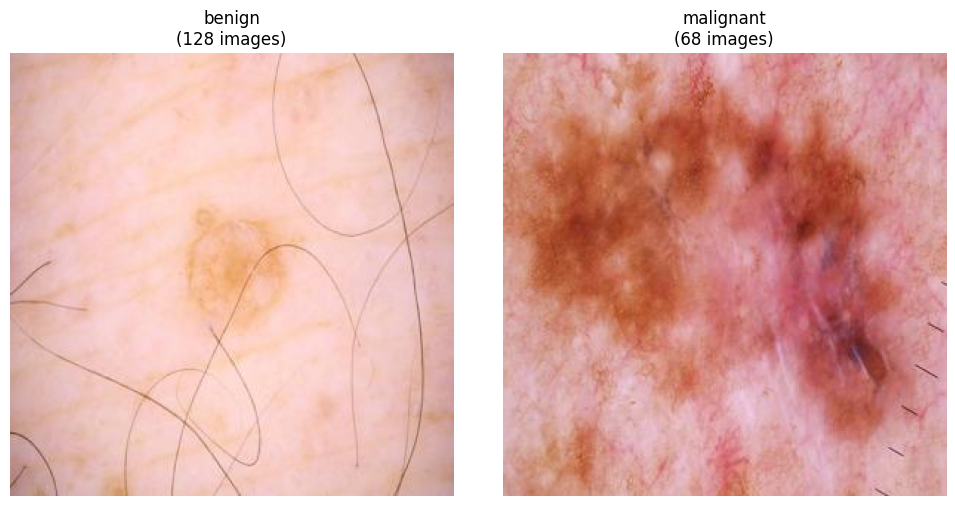

In [2]:
import os
from PIL import Image
import matplotlib.pyplot as plt

base_path = '/content/drive/MyDrive/Skin Cancer Detection Using Deep Learning/melanoma_cancer_dataset/train'

try:
    # List classes/folders in the train directory
    classes = os.listdir(base_path)
    print(f"Classes found: {classes}")

    # Display some images from each class
    fig, axes = plt.subplots(1, len(classes), figsize=(10, 5))
    if len(classes) == 1:
        axes = [axes]

    for i, class_name in enumerate(classes):
        class_path = os.path.join(base_path, class_name)
        if os.path.isdir(class_path):
            images = os.listdir(class_path)
            valid_images = [img for img in images if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
            if valid_images:
                img_path = os.path.join(class_path, valid_images[0])
                img = Image.open(img_path)
                axes[i].imshow(img)
                axes[i].set_title(f"{class_name}\n({len(valid_images)} images)")
                axes[i].axis('off')
            else:
                axes[i].text(0.5, 0.5, 'No images', ha='center', va='center')
                axes[i].set_title(class_name)
                axes[i].axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"An error occurred: {e}")

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define image parameters
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load training dataset (80% for training)
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load validation dataset (20% for testing/validation)
val_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 196 files belonging to 2 classes.
Using 157 files for training.
Found 196 files belonging to 2 classes.
Using 39 files for validation.


In [4]:
# Build the CNN architecture
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,993 (8.09 MB)

 Trainable params: 2,120,993 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 29s 6s/step - accuracy: 0.4076 - loss: 0.8178 - val_accuracy: 0.3846 - val_loss: 0.7101
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 544ms/step - accuracy: 0.6051 - loss: 0.6777 - val_accuracy: 0.6154 - val_loss: 0.6539
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 949ms/step - accuracy: 0.6624 - loss: 0.6370 - val_accuracy: 0.6154 - val_loss: 0.6829
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 647ms/step - accuracy: 0.6688 - loss: 0.6191 - val_accuracy: 0.6410 - val_loss: 0.6315
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 529ms/step - accuracy: 0.6752 - loss: 0.6155 - val_accuracy: 0.6410 - val_loss: 0.6101
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 551ms/step - accuracy: 0.6815 - loss: 0.5787 - val_accuracy: 0.6410 - val_loss: 0.5723
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 820ms/step - accuracy: 0.7197 - loss: 0.5486 - val_accuracy: 0.6410 - val_loss: 0.5342
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 532ms/step - accuracy: 0.7643 - loss: 0.4795 - val_accuracy: 0.7436 - val_loss: 0

In [6]:
# Evaluate and print the validation accuracy
loss, accuracy = model.evaluate(val_ds)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7179 - loss: 0.4503
Validation Accuracy: 71.79%


In [7]:
import numpy as np
from sklearn.metrics import classification_report

# Retrieve true labels and predictions from the validation dataset
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    # Convert sigmoid probabilities to binary predictions (0 or 1)
    preds_binary = (preds >= 0.5).astype(int).flatten()

    y_true.extend(labels.numpy())
    y_pred.extend(preds_binary)

# Get class names from dataset
target_names = val_ds.class_names

# Print the classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=target_names))

Classification Report:

              precision    recall  f1-score   support

      benign       0.69      1.00      0.81        24
   malignant       1.00      0.27      0.42        15

    accuracy                           0.72        39
   macro avg       0.84      0.63      0.62        39
weighted avg       0.81      0.72      0.66        39



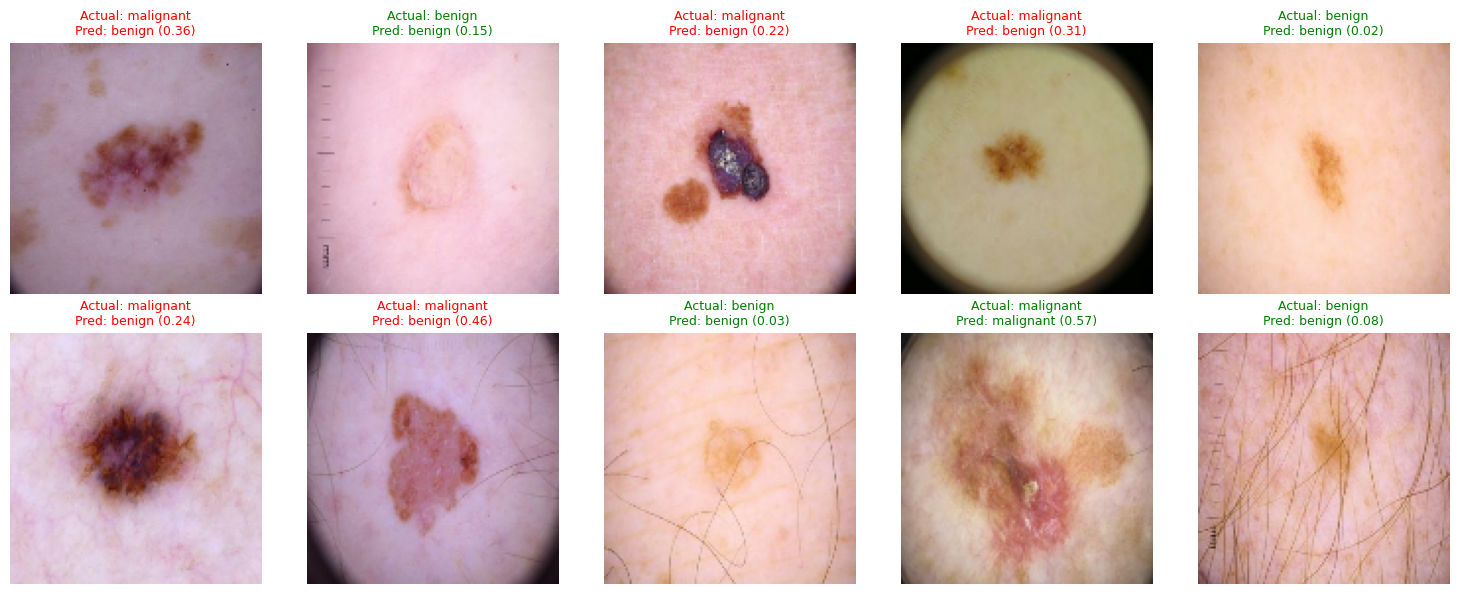

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Extract one batch of images and labels from the validation dataset
for images, labels in val_ds.take(1):
    # Get predictions for the entire batch
    preds = model.predict(images, verbose=0)

    # Display the first 10 images with actual vs predicted labels
    plt.figure(figsize=(15, 6))
    for i in range(10):
        ax = plt.subplot(2, 5, i + 1)
        # Rescale the image back to 0-255 if it was preprocessed
        img_display = images[i].numpy().astype("uint8")
        plt.imshow(img_display)

        actual_label = target_names[int(labels[i])]
        pred_prob = preds[i][0]
        predicted_label = target_names[1 if pred_prob >= 0.5 else 0]

        color = 'green' if actual_label == predicted_label else 'red'
        plt.title(f"Actual: {actual_label}\nPred: {predicted_label} ({pred_prob:.2f})", color=color, fontsize=9)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
    break